In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import json

In [2]:
from google.colab import files

uploaded = files.upload()

Saving nightlights_2012.png to nightlights_2012.png
Saving nightlights_2013.png to nightlights_2013.png
Saving nightlights_2014.png to nightlights_2014.png
Saving nightlights_2015.png to nightlights_2015.png
Saving nightlights_2016.png to nightlights_2016.png
Saving nightlights_2017.png to nightlights_2017.png
Saving nightlights_2018.png to nightlights_2018.png
Saving nightlights_2019.png to nightlights_2019.png
Saving nightlights_2020.png to nightlights_2020.png
Saving nightlights_2021.png to nightlights_2021.png
Saving nightlights_2022.png to nightlights_2022.png
Saving nightlights_2023.png to nightlights_2023.png


In [3]:
img_2012 = cv2.imread("nightlights_2012.png")
img_2013 = cv2.imread("nightlights_2013.png")
img_2014 = cv2.imread("nightlights_2014.png")
img_2015 = cv2.imread("nightlights_2015.png")
img_2016 = cv2.imread("nightlights_2016.png")
img_2017 = cv2.imread("nightlights_2017.png")
img_2018 = cv2.imread("nightlights_2018.png")
img_2019 = cv2.imread("nightlights_2019.png")
img_2020 = cv2.imread("nightlights_2020.png")
img_2021 = cv2.imread("nightlights_2021.png")
img_2022 = cv2.imread("nightlights_2022.png")
img_2023 = cv2.imread("nightlights_2023.png")

images = {
    2012: img_2012,
    2013: img_2013,
    2014: img_2014,
    2015: img_2015,
    2016: img_2016,
    2017: img_2017,
    2018: img_2018,
    2019: img_2019,
    2020: img_2020,
    2021: img_2021,
    2022: img_2022,
    2023: img_2023
}

for year, img in images.items():
    if img is None:
        raise ValueError(f"Image for {year} not found!")

    images[year] = cv2.cvtColor(
        img,
        cv2.COLOR_BGR2RGB
    )

    images[year] = cv2.resize(
        images[year],
        (1024, 512)
    )

print("All annual images loaded successfully!")

All annual images loaded successfully!


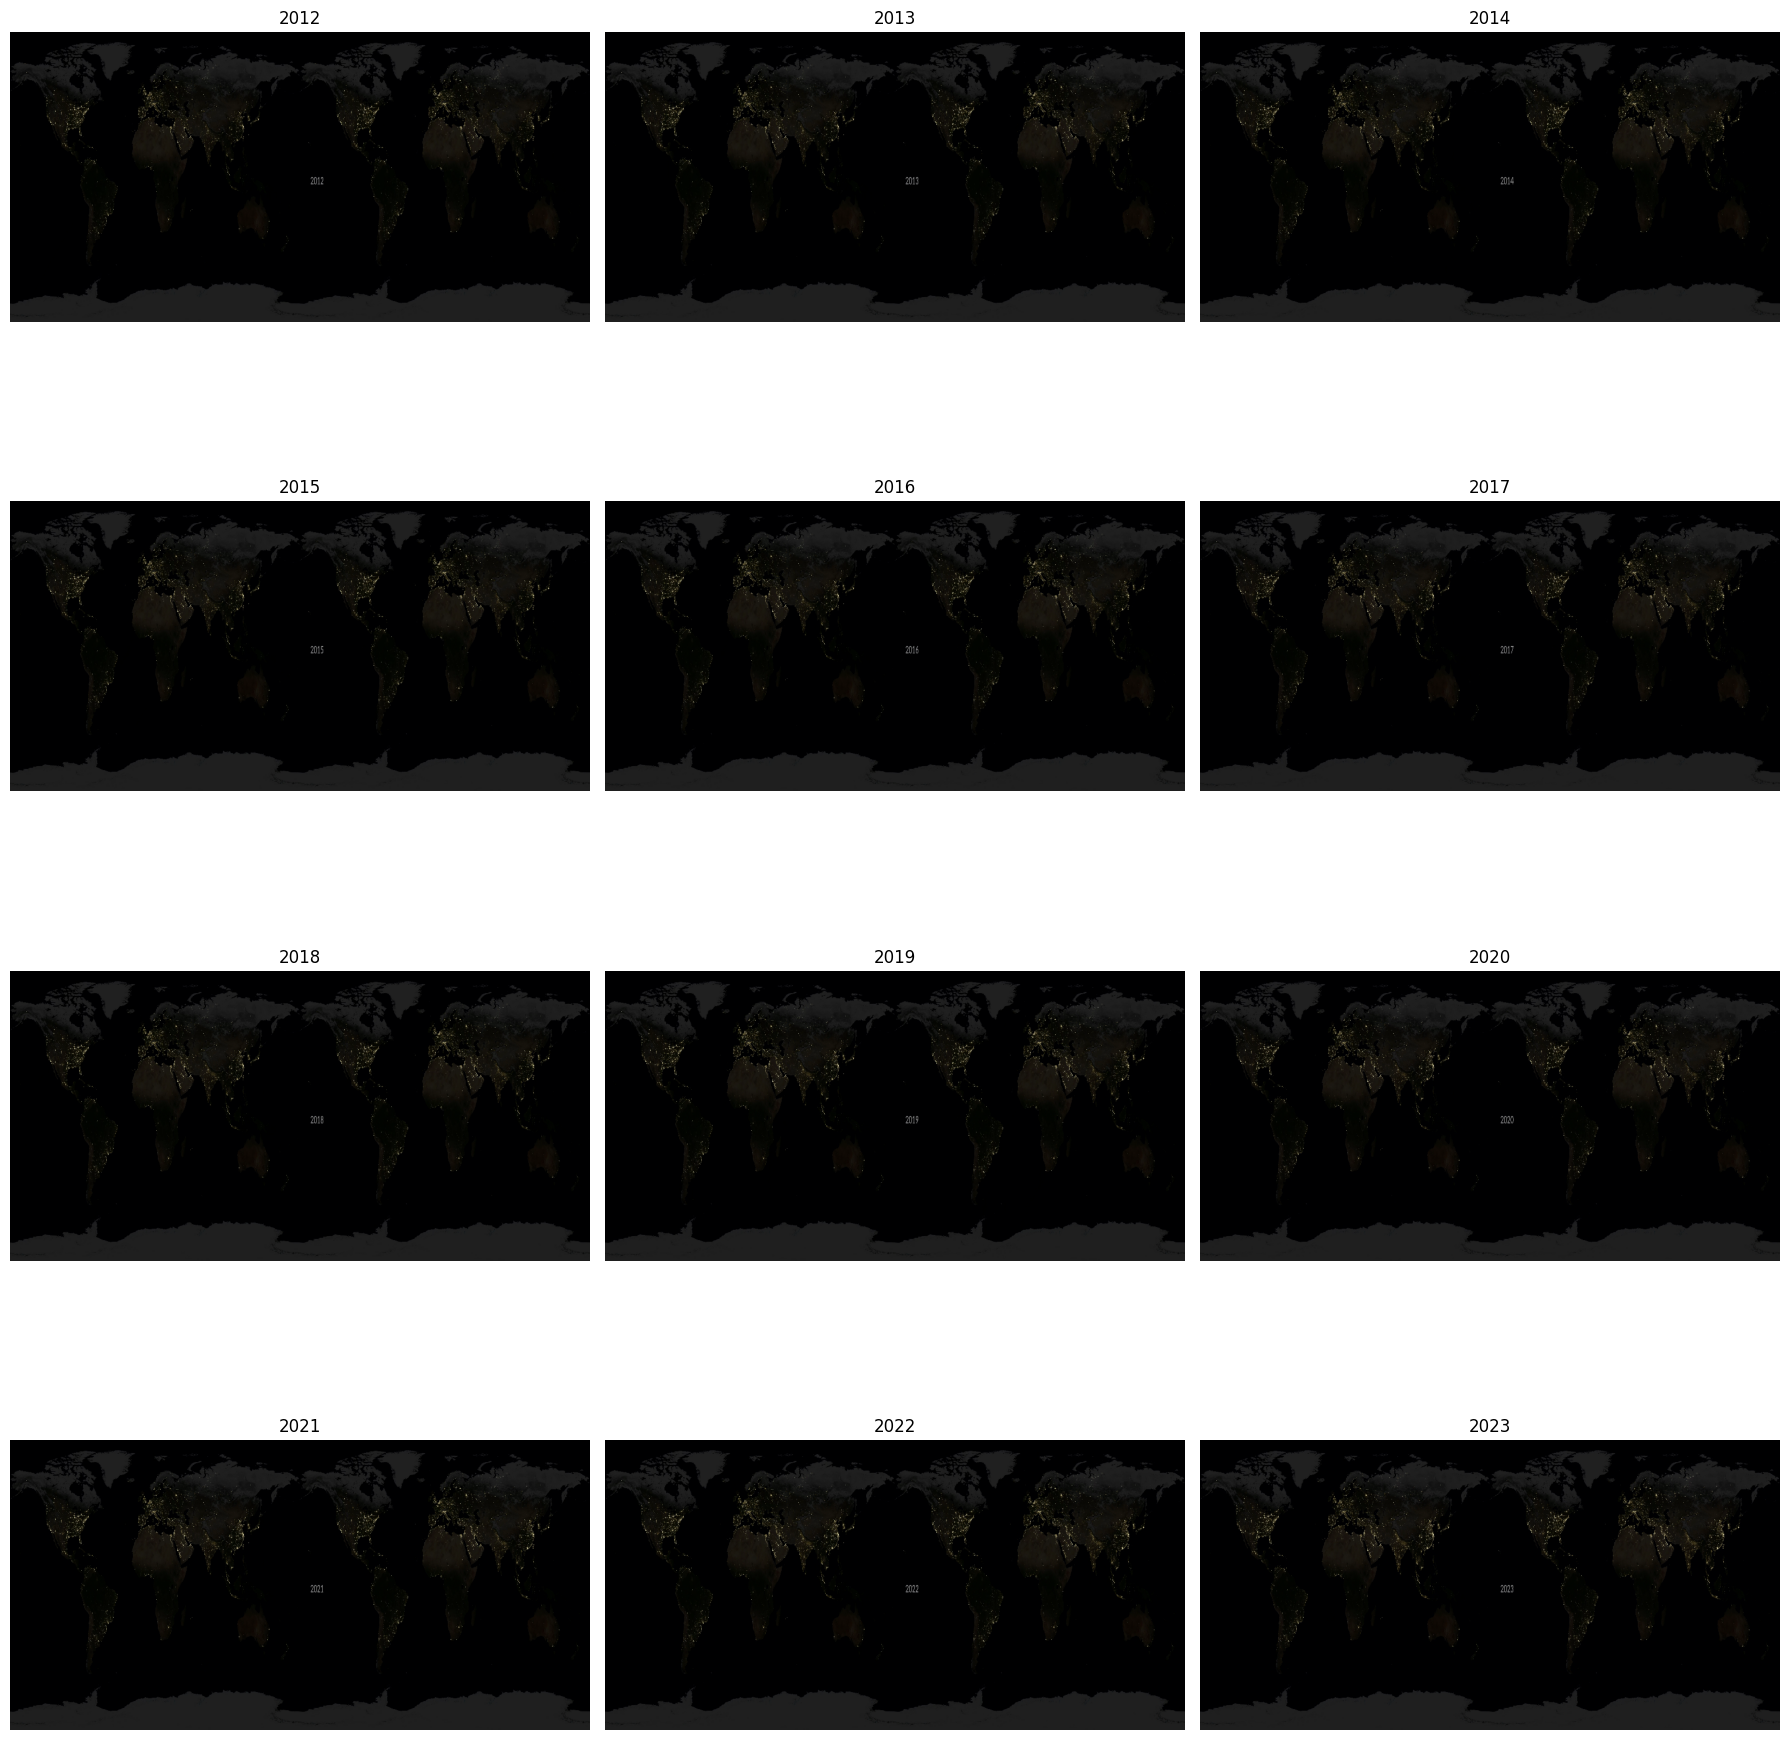

In [4]:
years = list(images.keys())

plt.figure(figsize=(18, 20))

for i, year in enumerate(years):

    plt.subplot(4, 3, i + 1)

    plt.imshow(images[year])

    plt.title(str(year))

    plt.axis("off")

plt.tight_layout()
plt.show()

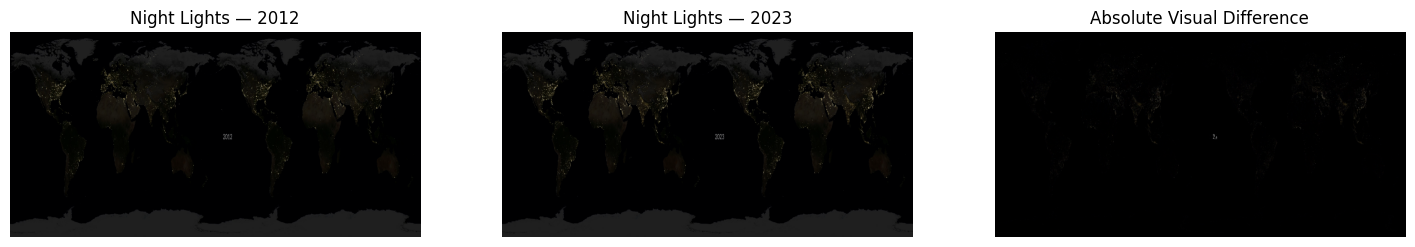

In [5]:
img_2012 = images[2012]
img_2023 = images[2023]

difference = cv2.absdiff(
    img_2012,
    img_2023
)

plt.figure(figsize=(18, 6))

plt.subplot(1, 3, 1)
plt.imshow(img_2012)
plt.title("Night Lights — 2012")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(img_2023)
plt.title("Night Lights — 2023")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(difference)
plt.title("Absolute Visual Difference")
plt.axis("off")

plt.show()

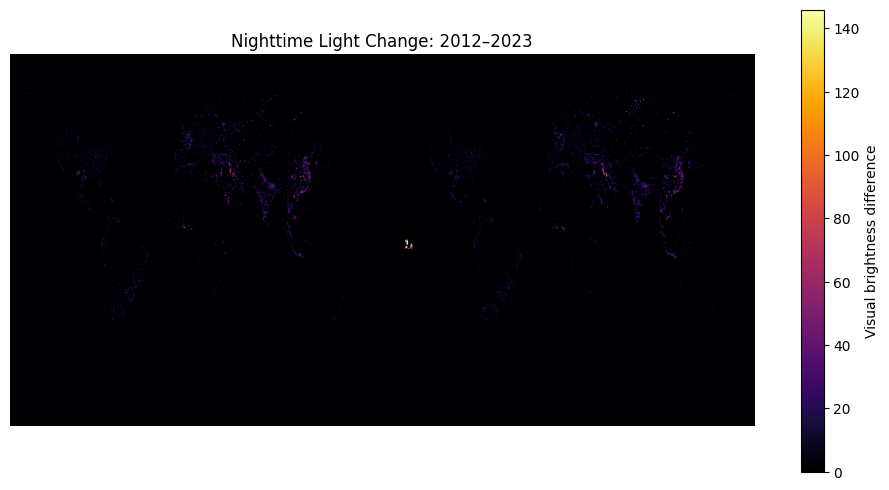

In [6]:
gray_2012 = cv2.cvtColor(
    images[2012],
    cv2.COLOR_RGB2GRAY
)

gray_2023 = cv2.cvtColor(
    images[2023],
    cv2.COLOR_RGB2GRAY
)

change_map = cv2.absdiff(
    gray_2012,
    gray_2023
)

plt.figure(figsize=(12, 6))

plt.imshow(
    change_map,
    cmap="inferno"
)

plt.colorbar(label="Visual brightness difference")

plt.title("Nighttime Light Change: 2012–2023")

plt.axis("off")

plt.show()

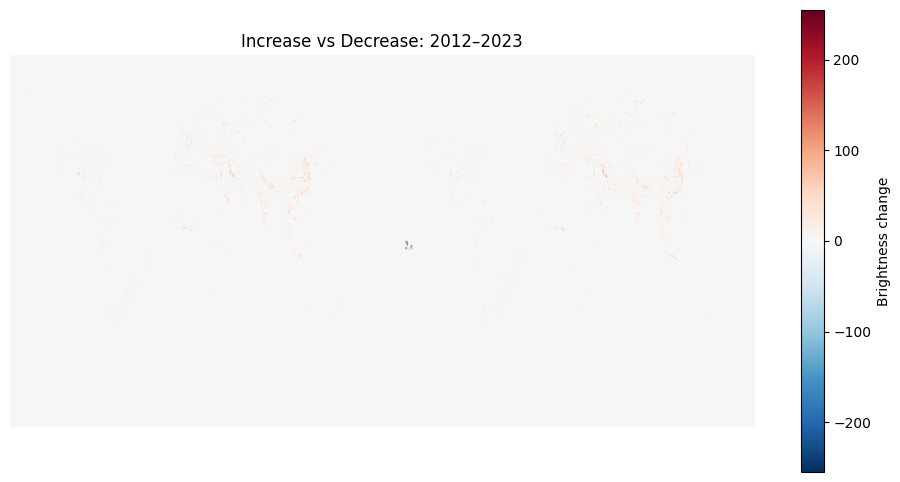

In [7]:
signed_change = (
    gray_2023.astype(np.float32)
    - gray_2012.astype(np.float32)
)

plt.figure(figsize=(12, 6))

plt.imshow(
    signed_change,
    cmap="RdBu_r",
    vmin=-255,
    vmax=255
)

plt.colorbar(label="Brightness change")

plt.title("Increase vs Decrease: 2012–2023")

plt.axis("off")

plt.show()

In [8]:
GRID_ROWS = 16
GRID_COLS = 32

h, w = signed_change.shape

region_changes = []

for r in range(GRID_ROWS):

    for c in range(GRID_COLS):

        y1 = r * h // GRID_ROWS
        y2 = (r + 1) * h // GRID_ROWS

        x1 = c * w // GRID_COLS
        x2 = (c + 1) * w // GRID_COLS

        region = signed_change[y1:y2, x1:x2]

        region_changes.append({

            "row": r,
            "col": c,

            "mean_change": float(
                np.mean(region)
            ),

            "change_magnitude": float(
                np.mean(np.abs(region))
            )

        })

region_df = pd.DataFrame(region_changes)

display(
    region_df.sort_values(
        "change_magnitude",
        ascending=False
    ).head(15)
)

,row,col,mean_change,change_magnitude
172,5,12,8.129883,8.506836
188,5,28,7.674805,8.182617
185,5,25,4.756836,5.870117
169,5,9,4.213867,5.198242
140,4,12,4.262695,4.975586
153,4,25,3.772461,4.831055
137,4,9,3.554688,4.822266
156,4,28,4.100586,4.754883
273,8,17,0.185547,4.748047
171,5,11,3.343750,3.878906


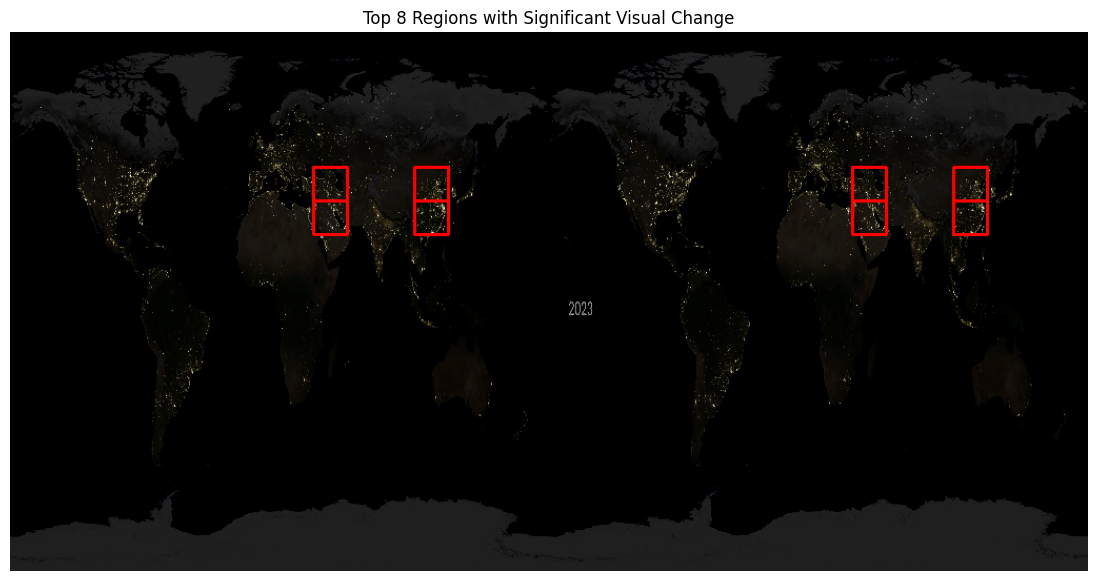

In [9]:
top_regions = region_df.nlargest(
    8,
    "change_magnitude"
)

highlight = images[2023].copy()

for _, region in top_regions.iterrows():

    r = int(region["row"])
    c = int(region["col"])

    y1 = r * h // GRID_ROWS
    y2 = (r + 1) * h // GRID_ROWS

    x1 = c * w // GRID_COLS
    x2 = (c + 1) * w // GRID_COLS

    cv2.rectangle(
        highlight,
        (x1, y1),
        (x2, y2),
        (255, 0, 0),
        2
    )

plt.figure(figsize=(14, 7))

plt.imshow(highlight)

plt.title("Top 8 Regions with Significant Visual Change")

plt.axis("off")

plt.show()

In [10]:
annual_changes = {}

for i in range(1, len(years)):

    previous_year = years[i - 1]
    current_year = years[i]

    previous = cv2.cvtColor(
        images[previous_year],
        cv2.COLOR_RGB2GRAY
    )

    current = cv2.cvtColor(
        images[current_year],
        cv2.COLOR_RGB2GRAY
    )

    change = (
        current.astype(np.float32)
        - previous.astype(np.float32)
    )

    annual_changes[current_year] = change

    print(
        f"{previous_year} → {current_year}:",
        "Mean change =",
        round(float(np.mean(np.abs(change))), 3)
    )

2012 → 2013: Mean change = 0.11
2013 → 2014: Mean change = 0.272
2014 → 2015: Mean change = 0.266
2015 → 2016: Mean change = 0.079
2016 → 2017: Mean change = 0.184
2017 → 2018: Mean change = 0.162
2018 → 2019: Mean change = 0.263
2019 → 2020: Mean change = 0.192
2020 → 2021: Mean change = 0.181
2021 → 2022: Mean change = 0.295
2022 → 2023: Mean change = 0.196


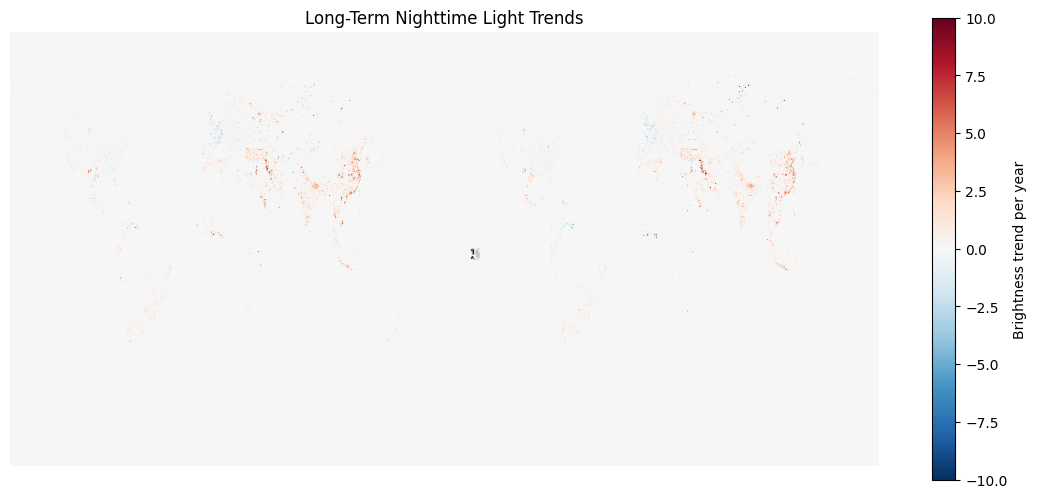

In [11]:
stack = np.stack([
    cv2.cvtColor(
        images[year],
        cv2.COLOR_RGB2GRAY
    ).astype(np.float32)
    for year in years
])

time = np.array(years, dtype=np.float32)

time_centered = time - time.mean()

trend_map = np.tensordot(
    time_centered,
    stack,
    axes=(0, 0)
) / np.sum(time_centered ** 2)

plt.figure(figsize=(14, 6))

plt.imshow(
    trend_map,
    cmap="RdBu_r",
    vmin=-10,
    vmax=10
)

plt.colorbar(label="Brightness trend per year")

plt.title("Long-Term Nighttime Light Trends")

plt.axis("off")

plt.show()

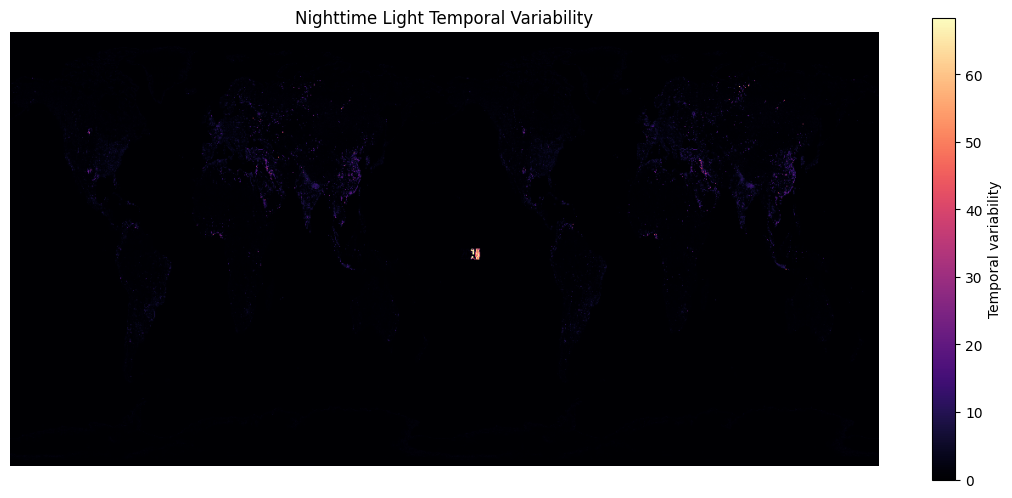

In [12]:
# Calculate the average temporal brightness at every pixel
mean_map = np.mean(stack, axis=0)

# Calculate temporal standard deviation
std_map = np.std(stack, axis=0)

# Identify pixels with unusually high temporal variability
variability_map = std_map

plt.figure(figsize=(14, 6))

plt.imshow(
    variability_map,
    cmap="magma"
)

plt.colorbar(label="Temporal variability")

plt.title("Nighttime Light Temporal Variability")

plt.axis("off")

plt.show()

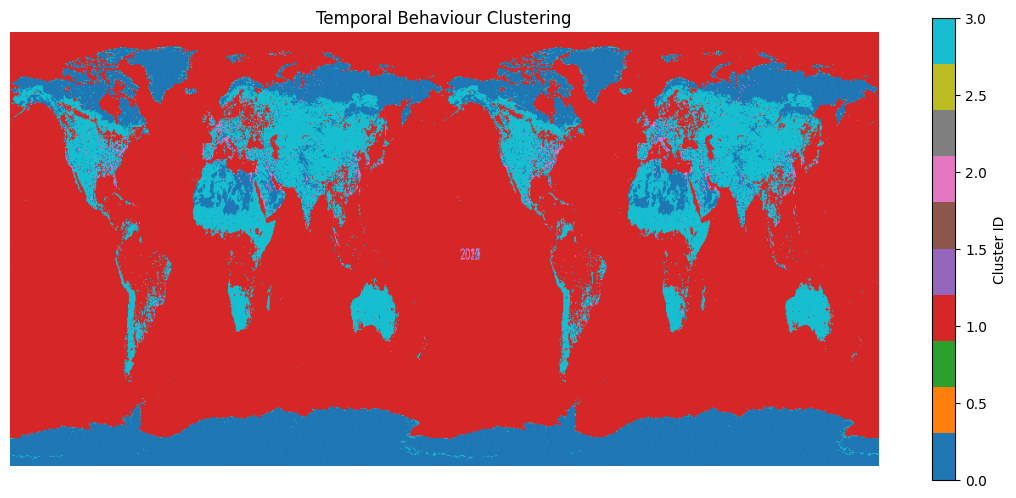

In [13]:
from sklearn.cluster import MiniBatchKMeans
from sklearn.preprocessing import StandardScaler

# Each pixel becomes a feature vector:
# [2012 brightness, 2013 brightness, ..., 2023 brightness]

pixel_features = stack.reshape(
    len(years),
    -1
).T

# Sample pixels to keep processing lightweight
rng = np.random.default_rng(42)

sample_size = min(
    50000,
    len(pixel_features)
)

sample_indices = rng.choice(
    len(pixel_features),
    size=sample_size,
    replace=False
)

sample = pixel_features[sample_indices]

scaler = StandardScaler()

sample_scaled = scaler.fit_transform(sample)

kmeans = MiniBatchKMeans(
    n_clusters=4,
    random_state=42,
    batch_size=2048,
    n_init=5
)

kmeans.fit(sample_scaled)

# Predict cluster for every pixel
all_scaled = scaler.transform(pixel_features)

cluster_map = kmeans.predict(
    all_scaled
).reshape(stack.shape[1:])

plt.figure(figsize=(14, 6))

plt.imshow(
    cluster_map,
    cmap="tab10"
)

plt.colorbar(label="Cluster ID")

plt.title("Temporal Behaviour Clustering")

plt.axis("off")

plt.show()

In [14]:
import json

output = {

    "project": "Earth Jukebox: Change Mode",

    "years": years,

    "grid": {
        "rows": GRID_ROWS,
        "cols": GRID_COLS
    },

    "regions": []

}

for r in range(GRID_ROWS):

    for c in range(GRID_COLS):

        y1 = r * h // GRID_ROWS
        y2 = (r + 1) * h // GRID_ROWS

        x1 = c * w // GRID_COLS
        x2 = (c + 1) * w // GRID_COLS

        temporal_values = []

        for i in range(len(years)):

            region = stack[i, y1:y2, x1:x2]

            temporal_values.append(
                float(np.mean(region))
            )

        annual_change = np.diff(
            temporal_values
        )

        region = {

            "region_id": r * GRID_COLS + c,

            "row": r,
            "col": c,

            "values": temporal_values,

            "annual_change": [
                0.0
            ] + annual_change.tolist(),

            "trend": float(
                np.mean(
                    trend_map[y1:y2, x1:x2]
                )
            ),

            "volatility": float(
                np.std(temporal_values)
            ),

            "cluster": int(
                np.bincount(
                    cluster_map[y1:y2, x1:x2].astype(int).ravel(),
                    minlength=4
                ).argmax()
            )

        }

        output["regions"].append(region)


with open(
    "earth_jukebox_data.json",
    "w"
) as f:

    json.dump(output, f)

print("Dataset exported successfully!")

Dataset exported successfully!


In [15]:
from google.colab import files

files.download("earth_jukebox_data.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

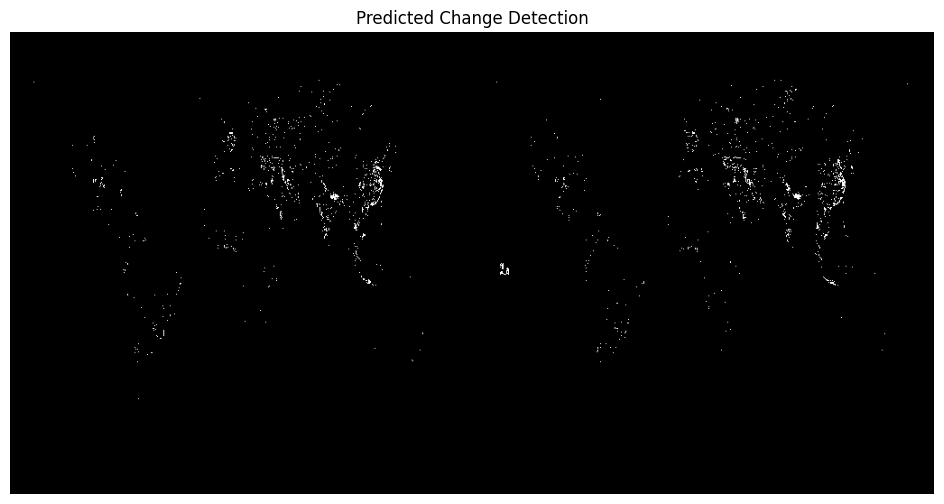

In [31]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Absolute brightness difference
change_map = np.abs(signed_change)

# Threshold for detecting visual changes
THRESHOLD = 20

predicted_mask = (
    change_map > THRESHOLD
).astype(np.uint8)

plt.figure(figsize=(12, 6))

plt.imshow(predicted_mask, cmap="gray")

plt.title("Predicted Change Detection")

plt.axis("off")

plt.show()

Saving ground_truth.png to ground_truth.png


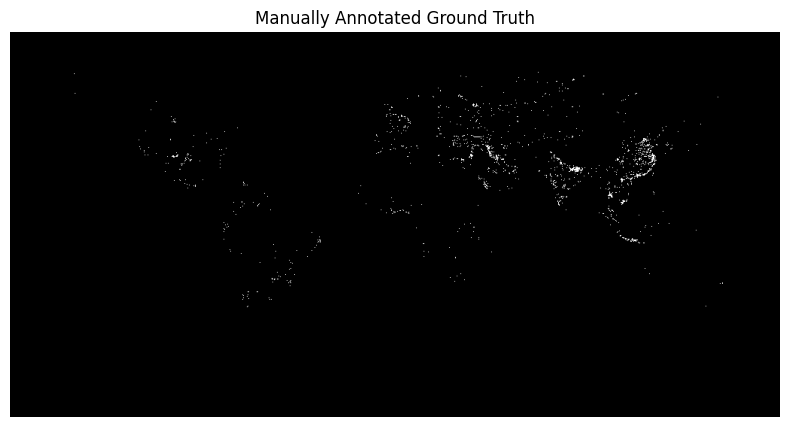

In [32]:
from google.colab import files

uploaded = files.upload()

ground_truth = cv2.imread(
    "ground_truth.png",
    cv2.IMREAD_GRAYSCALE
)

ground_truth = cv2.resize(
    ground_truth,
    (1024, 512)
)

ground_truth_mask = (
    ground_truth > 127
).astype(np.uint8)

plt.figure(figsize=(12, 5))

plt.imshow(ground_truth_mask, cmap="gray")

plt.title("Manually Annotated Ground Truth")

plt.axis("off")

plt.show()

In [33]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

y_true = ground_truth_mask.flatten()
y_pred = predicted_mask.flatten()

accuracy = accuracy_score(y_true, y_pred)

precision = precision_score(
    y_true,
    y_pred,
    zero_division=0
)

recall = recall_score(
    y_true,
    y_pred,
    zero_division=0
)

f1 = f1_score(
    y_true,
    y_pred,
    zero_division=0
)

tn, fp, fn, tp = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1]
).ravel()

iou = tp / (tp + fp + fn) if tp + fp + fn else 0

print("========== CV EVALUATION ==========")

print(f"Accuracy:  {accuracy * 100:.2f}%")
print(f"Precision: {precision * 100:.2f}%")
print(f"Recall:    {recall * 100:.2f}%")
print(f"F1 Score:  {f1 * 100:.2f}%")
print(f"IoU:       {iou * 100:.2f}%")

print("\nConfusion Matrix:")
print("True Positive:", tp)
print("False Positive:", fp)
print("False Negative:", fn)
print("True Negative:", tn)

========== CV EVALUATION ==========
Accuracy:  99.28%
Precision: 0.82%
Recall:    1.13%
F1 Score:  0.95%
IoU:       0.48%

Confusion Matrix:
True Positive: 18
False Positive: 2179
False Negative: 1581
True Negative: 520510


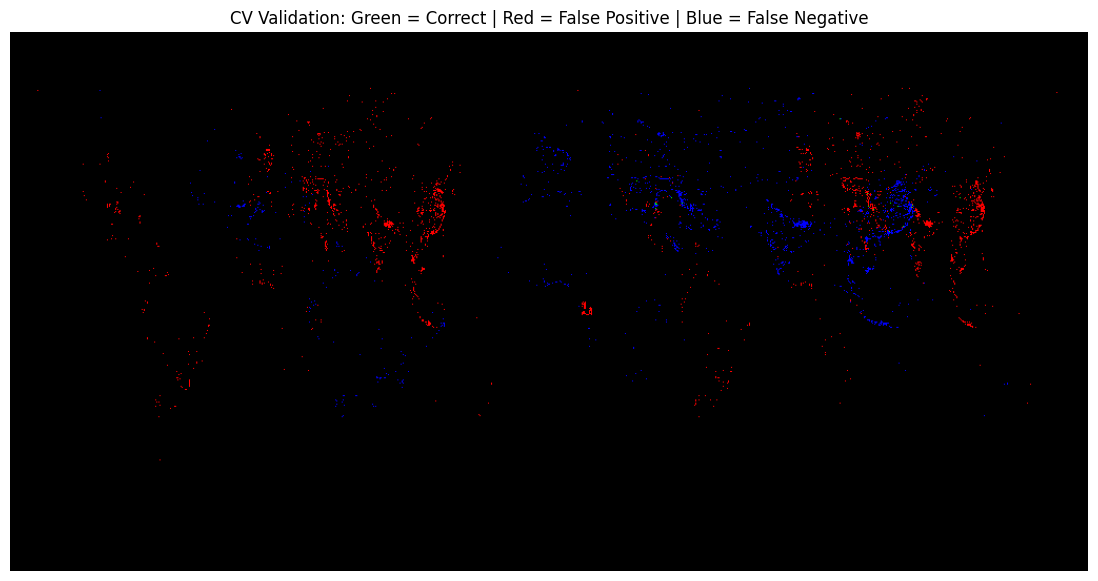

In [34]:
comparison = np.zeros(
    (512, 1024, 3),
    dtype=np.uint8
)

# True positive: green
comparison[
    (ground_truth_mask == 1) &
    (predicted_mask == 1)
] = [0, 255, 0]

# False positive: red
comparison[
    (ground_truth_mask == 0) &
    (predicted_mask == 1)
] = [255, 0, 0]

# False negative: blue
comparison[
    (ground_truth_mask == 1) &
    (predicted_mask == 0)
] = [0, 0, 255]

plt.figure(figsize=(15, 7))

plt.imshow(comparison)

plt.title(
    "CV Validation: Green = Correct | Red = False Positive | Blue = False Negative"
)

plt.axis("off")

plt.show()

In [35]:
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score
)

sample_labels = kmeans.labels_

silhouette = silhouette_score(
    sample_scaled,
    sample_labels
)

db_score = davies_bouldin_score(
    sample_scaled,
    sample_labels
)

print("Silhouette Score:", round(silhouette, 4))
print("Davies-Bouldin Index:", round(db_score, 4))

Silhouette Score: 0.8552
Davies-Bouldin Index: 0.5497


In [16]:
# for year in years:

#     img = images[year]

#     print(
#         year,
#         "Shape:", img.shape,
#         "Mean brightness:", round(float(np.mean(img)), 2)
#     )

2012 Shape: (512, 1024, 3) Mean brightness: 7.61
2013 Shape: (512, 1024, 3) Mean brightness: 7.63
2014 Shape: (512, 1024, 3) Mean brightness: 7.65
2015 Shape: (512, 1024, 3) Mean brightness: 7.65
2016 Shape: (512, 1024, 3) Mean brightness: 7.65
2017 Shape: (512, 1024, 3) Mean brightness: 7.73
2018 Shape: (512, 1024, 3) Mean brightness: 7.68
2019 Shape: (512, 1024, 3) Mean brightness: 7.7
2020 Shape: (512, 1024, 3) Mean brightness: 7.75
2021 Shape: (512, 1024, 3) Mean brightness: 7.71
2022 Shape: (512, 1024, 3) Mean brightness: 7.78
2023 Shape: (512, 1024, 3) Mean brightness: 7.9


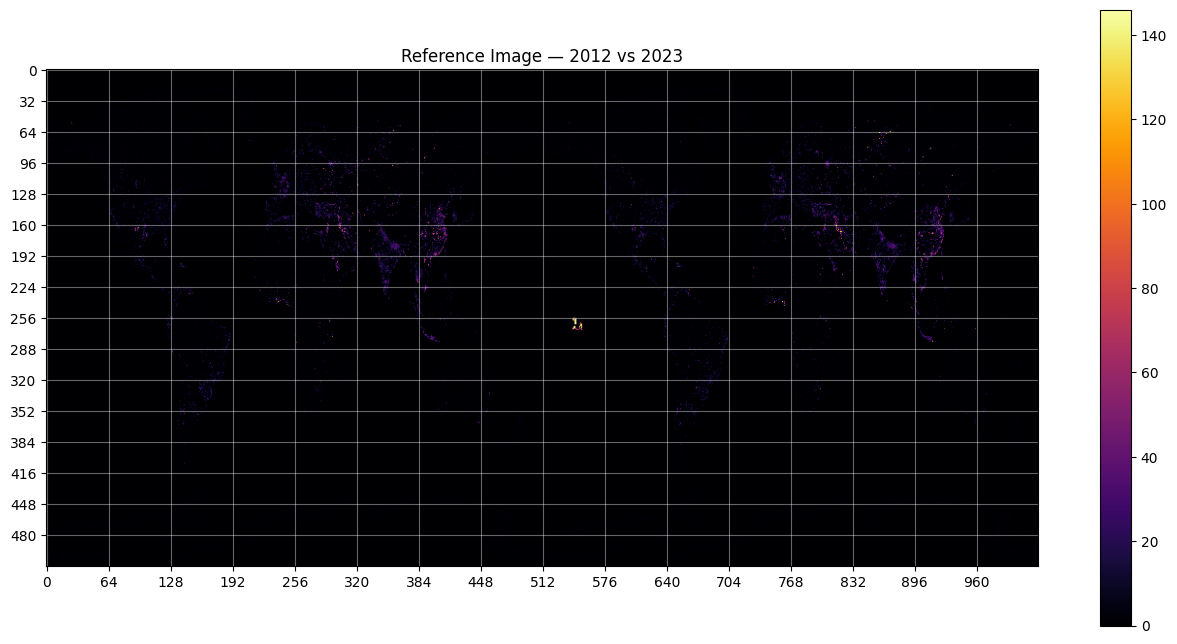

In [17]:
# import matplotlib.pyplot as plt

# plt.figure(figsize=(16, 8))

# plt.imshow(
#     change_map,
#     cmap="inferno"
# )

# plt.title("Reference Image — 2012 vs 2023")

# plt.xticks(np.arange(0, 1024, 64))
# plt.yticks(np.arange(0, 512, 32))

# plt.grid(color="white", alpha=0.4)

# plt.colorbar()

# plt.show()

In [18]:
# # Example labels only.
# # Replace these with cells you have actually inspected.

# ground_truth = {
#     (2, 5): 1,
#     (3, 8): 1,
#     (5, 12): 0,
#     (7, 16): 1,
#     (9, 20): 0,
#     (11, 24): 1,
#     (13, 10): 0,
#     (14, 27): 1
# }

# # 1 = Significant visual change
# # 0 = No significant visual change

In [19]:
# from sklearn.metrics import (
#     accuracy_score,
#     precision_score,
#     recall_score,
#     f1_score,
#     confusion_matrix,
#     classification_report
# )

# predictions = []
# actual = []

# for (r, c), label in ground_truth.items():

#     y1 = r * h // GRID_ROWS
#     y2 = (r + 1) * h // GRID_ROWS

#     x1 = c * w // GRID_COLS
#     x2 = (c + 1) * w // GRID_COLS

#     region = change_map[y1:y2, x1:x2]

#     magnitude = np.mean(region)

#     # Illustrative threshold; tune using training/reference cells
#     predicted_label = int(magnitude > 15)

#     predictions.append(predicted_label)
#     actual.append(label)

# print("Accuracy:", accuracy_score(actual, predictions))
# print("Precision:", precision_score(actual, predictions, zero_division=0))
# print("Recall:", recall_score(actual, predictions, zero_division=0))
# print("F1 Score:", f1_score(actual, predictions, zero_division=0))

# print("\nConfusion Matrix:")
# print(confusion_matrix(actual, predictions))

# print("\nDetailed Report:")
# print(classification_report(actual, predictions, zero_division=0))

Accuracy: 0.375
Precision: 0.0
Recall: 0.0
F1 Score: 0.0

Confusion Matrix:
[[3 0]
 [5 0]]

Detailed Report:
              precision    recall  f1-score   support

           0       0.38      1.00      0.55         3
           1       0.00      0.00      0.00         5

    accuracy                           0.38         8
   macro avg       0.19      0.50      0.27         8
weighted avg       0.14      0.38      0.20         8



In [20]:
# from scipy.stats import spearmanr

# actual_trends = []
# estimated_trends = []

# for r in range(GRID_ROWS):

#     for c in range(GRID_COLS):

#         y1 = r * h // GRID_ROWS
#         y2 = (r + 1) * h // GRID_ROWS

#         x1 = c * w // GRID_COLS
#         x2 = (c + 1) * w // GRID_COLS

#         values = []

#         for year in years:

#             region = cv2.cvtColor(
#                 images[year],
#                 cv2.COLOR_RGB2GRAY
#             )[y1:y2, x1:x2]

#             values.append(np.mean(region))

#         actual_trend = np.polyfit(
#             years,
#             values,
#             1
#         )[0]

#         estimated_trend = np.mean(
#             trend_map[y1:y2, x1:x2]
#         )

#         actual_trends.append(actual_trend)
#         estimated_trends.append(estimated_trend)

# correlation, p_value = spearmanr(
#     actual_trends,
#     estimated_trends
# )

# print("Trend rank correlation:", correlation)
# print("P-value:", p_value)

Trend rank correlation: 0.9993475338333426
P-value: 0.0


In [21]:
# from sklearn.metrics import silhouette_score

# sample_labels = kmeans.labels_

# score = silhouette_score(
#     sample_scaled,
#     sample_labels
# )

# print("Silhouette Score:", round(score, 4))

Silhouette Score: 0.8552
